# HW5 송민준 · 24013813

전처리 재현 (단계 ①~④) + 새 질문 셋 (단계 ⑤~⑦)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import platform

# 그림 속 한글이 네모로 나오지 않게 (운영체제별 글꼴)
fonts = {"Windows": "Malgun Gothic",
         "Darwin": "AppleGothic"}
name = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["font.family"] = name
plt.rcParams["axes.unicode_minus"] = False

## 단계 ① 읽고 날짜 세 칸을 날짜로

In [2]:
df = pd.read_csv("sales_data.csv")
dates = ["order_date", "shipping_date", "delivery_date"]
for col in dates:
    df[col] = pd.to_datetime(df[col])
df.shape

(1030, 14)

## 단계 ② 중복 행 제거

In [3]:
before = len(df)
df = df.drop_duplicates()
print(before, "->", len(df))

1030 -> 1004


## 단계 ③ 수량 > 100 인 줄의 수량을 금액 ÷ 단가로 복원

In [4]:
bad = df["quantity"] > 100
df.loc[bad, "quantity"] = (df.loc[bad, "total_sales"] / df.loc[bad, "unit_price"]).round().astype(int)
diff = (df["total_sales"] - df["quantity"] * df["unit_price"]).abs()
print("고친 줄 :", bad.sum(), " 수량 최대 :", df["quantity"].max(), " 총액 안 맞는 줄 :", (diff > 1).sum())

고친 줄 : 22  수량 최대 : 99  총액 안 맞는 줄 : 0


## 단계 ④ date_error 추가, sales_clean.csv 저장

In [5]:
df["date_error"] = df["delivery_date"] < df["shipping_date"]
print(df["date_error"].sum(), "건")
df.to_csv("sales_clean.csv", index=False)
df.shape

147 건


(1004, 15)

## 단계 ⑤ 배송 기간 (도착일 − 배송일) 은 보통 며칠인가

계산된 줄 : 852  평균 : 22.05  중앙값 : 2.0


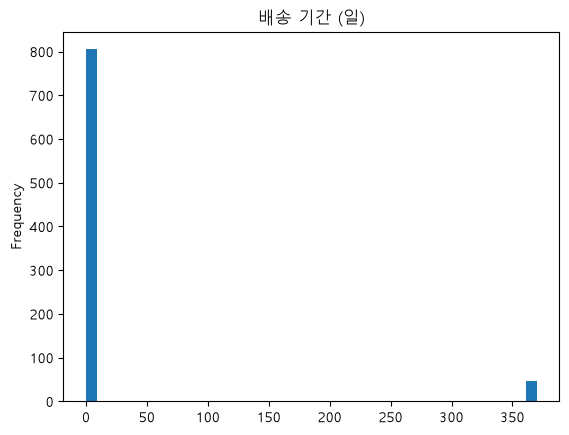

In [6]:
ok = df[~df["date_error"]]                # date_error 가 아닌 줄만
days = (ok["delivery_date"] - ok["shipping_date"]).dt.days
print("계산된 줄 :", days.count(), " 평균 :", round(days.mean(), 2), " 중앙값 :", days.median())
days.plot.hist(bins=40, title="배송 기간 (일)")
plt.show()

### 오른쪽 끝 덩어리 들여다보기

In [7]:
big = days[days > 300]
print("덩어리 :", len(big), "줄,", big.min(), "~", big.max(), "일")
print("그 사이 6 ~ 363 일 :", ((days > 5) & (days < 364)).sum(), "줄")
print("덩어리를 뺀 나머지 :", days[days <= 300].min(), "~", days[days <= 300].max(), "일")
ok.loc[big.index, dates].assign(days=big).head()

덩어리 : 47 줄, 364.0 ~ 370.0 일
그 사이 6 ~ 363 일 : 0 줄
덩어리를 뺀 나머지 : 0.0 ~ 5.0 일


,order_date,shipping_date,delivery_date,days
11,2023-01-12,2023-01-15,2024-01-15,365.0
20,2023-01-21,2023-01-23,2024-01-27,369.0
29,2023-01-30,2023-02-03,2024-02-03,365.0
41,2023-02-11,2023-02-14,2024-02-17,368.0
68,2023-03-10,2023-03-14,2024-03-12,364.0


In [8]:
# 도착일에서 1년을 빼 보면 나머지 줄과 같은 범위로 돌아오는가
# df 와 sales_clean.csv 는 그대로 두고 이 질문 안에서만 고친다
fixed = ok["delivery_date"].copy()
fixed[big.index] = fixed[big.index] - pd.DateOffset(years=1)
days2 = (fixed - ok["shipping_date"]).dt.days
print("1년을 뺀 덩어리 :", days2[big.index].min(), "~", days2[big.index].max(), "일")
print("그래도 도착일이 빠른 줄 :", (days2 < 0).sum())

days2 = days2[days2 >= 0]                 # 음수는 date_error 와 같은 경우라 뺀다
print("처리 뒤 줄 :", days2.count(), " 평균 :", round(days2.mean(), 2), " 중앙값 :", days2.median())

1년을 뺀 덩어리 : -2.0 ~ 5.0 일
그래도 도착일이 빠른 줄 : 7
처리 뒤 줄 : 845  평균 : 1.92  중앙값 : 2.0


**답** 배송 기간은 보통 2일이다. 처음에는 평균 22.05일, 중앙값 2일로 크게 달랐는데, 364 ~ 370일에 몰린 47줄이 평균만 끌어올렸기 때문이다.

**처리와 근거** 6 ~ 363일이 0줄이라 덩어리가 따로 떨어져 있고 1년을 빼면 −2 ~ 5일로 돌아오므로, 도착일의 연도가 1년 밀린 오기로 보고 1년을 빼 복원했다. 그래도 도착일이 빠른 7줄은 제외해 845줄에서 평균 1.92일, 중앙값 2일이다.

## 단계 ⑥ 만족도가 낮을수록 반품이 많은가

satisfaction
1.0     7.6
2.0    12.0
3.0     7.8
4.0     8.7
5.0     6.9
Name: status, dtype: float64
점수별 반품 건수 : [17, 22, 15, 15, 14]


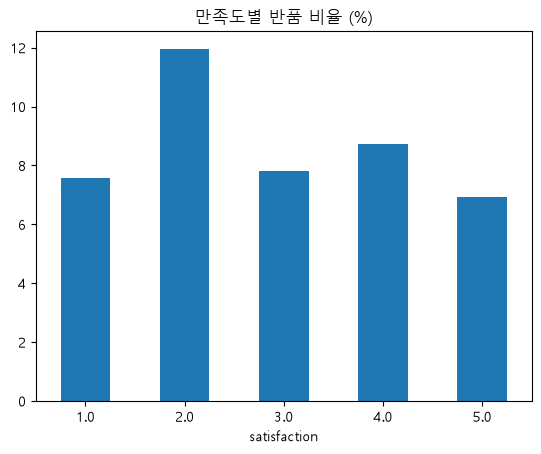

In [9]:
rate = (df["status"] == "반품").groupby(df["satisfaction"]).mean() * 100
print(rate.round(1))
print("점수별 반품 건수 :", (df["status"] == "반품").groupby(df["satisfaction"]).sum().tolist())
rate.plot.bar(title="만족도별 반품 비율 (%)", rot=0)
plt.show()

**답** 아니다. 반품 비율은 1점 7.6%, 2점 12.0%, 3점 7.8%, 4점 8.7%, 5점 6.9%로, 만족도가 낮을수록 높아지지 않는다.

가장 높은 것은 2점이고, 1점은 3 · 4점보다 낮다. 점수마다 반품은 14 ~ 22건뿐이며, 만족도가 빈 30줄은 계산에서 빠졌다.

## 단계 ⑦ 카테고리 매출 1위의 이유는 건수 · 단가 · 수량 중 무엇인가

In [10]:
table = df.groupby("category").agg(건수=("total_sales", "count"),
                                   매출합=("total_sales", "sum"),
                                   평균단가=("unit_price", "mean"),
                                   평균수량=("quantity", "mean")).sort_values("매출합", ascending=False)
table["매출합"] = table["매출합"] / 1e8    # 억 원 단위
table.round({"매출합": 1, "평균단가": 0, "평균수량": 1})

,건수,매출합,평균단가,평균수량
category,,,,
가구,213,28.4,257323.0,51.0
식품,210,25.1,255233.0,47.3
전자제품,207,24.7,249652.0,48.0
도서,204,24.5,238501.0,49.5
의류,170,21.8,249447.0,51.6


In [11]:
# 1위가 2위 · 다섯 카테고리 평균보다 몇 % 큰가
compare = pd.DataFrame({"2위 대비 (%)": (table.iloc[0] / table.iloc[1] - 1) * 100,
                        "평균 대비 (%)": (table.iloc[0] / table.mean() - 1) * 100})
compare.round(1)

,2위 대비 (%),평균 대비 (%)
건수,1.4,6.1
매출합,13.1,14.1
평균단가,0.8,2.9
평균수량,7.9,3.1


**답** 1위 가구 (28.4억) 는 건수 213건 · 평균 단가 257,323원이 1위, 평균 수량 51.0개가 2위로, 세 칸 모두 평균보다 약 3 ~ 6% 높아 한 칸만의 결과가 아니다.

차이가 가장 큰 칸은 비교 대상에 따라 다르다. 평균과 비교하면 건수 (+6.1%), 2위 식품과 비교하면 수량 (+7.9%, 건수 +1.4%, 단가 +0.8%) 이다.